# Titanic - Machine Learning from Disaster

## Project Overview

This project aims to predict whether a passenger survived the Titanic disaster using machine learning techniques.

The dataset is provided by the [Kaggle Titanic Competition](https://www.kaggle.com/competitions/titanic).

A Logistic Regression model is trained using passenger information such as:

- Passenger class
- Sex
- Age
- Number of siblings and spouses
- Number of parents and children
- Fare
- Port of embarkation

The model is evaluated using a validation set, and the final predictions are saved in a CSV file for Kaggle submission.

## 1. Import Libraries

Import the required libraries for data manipulation, visualization, model training, and evaluation.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 2. Load Dataset

Load the training and test datasets using Pandas.

- `train.csv`: Contains passenger information and survival labels.
- `test.csv`: Contains passenger information without survival labels.

In [4]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

## 3. Feature Selection

Select relevant passenger features for training the model.

The target variable is `Survived`, which indicates whether a passenger survived the Titanic disaster:

- `0`: Did not survive
- `1`: Survived

In [5]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X = train[features].copy()
y = train["Survived"]

## 4. Data Preprocessing

Prepare the selected features for machine learning by handling missing values and encoding categorical variables.

The preprocessing steps include:

- Filling missing `Age` values with the median.
- Filling missing `Embarked` values with the most frequent category.
- Converting `Sex` into numerical values.
- Applying one-hot encoding to `Embarked`.

In [6]:
# Handle missing values
X["Age"] = X["Age"].fillna(X["Age"].median())
X["Embarked"] = X["Embarked"].fillna(X["Embarked"].mode()[0])

# Encode Sex
X["Sex"] = X["Sex"].map({
    "male": 0,
    "female": 1
})

# One-hot encode Embarked
X = pd.get_dummies(
    X,
    columns=["Embarked"],
    dtype=int
)

## 5. Train-Validation Split

Split the dataset into training and validation sets.

- 80% of the data is used for training.
- 20% is used for validation.

Stratified splitting is applied to preserve the original class distribution in both sets.

In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## 6. Model Training

Train a Logistic Regression model using the training dataset.

Logistic Regression is a supervised machine learning algorithm commonly used for binary classification tasks.

In [8]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

## 7. Model Evaluation

Evaluate the trained model using the validation dataset.

The model's performance is measured using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

In [10]:
y_pred = model.predict(X_val)

accuracy = accuracy_score(y_val, y_pred)

print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.8044692737430168


In [11]:
print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



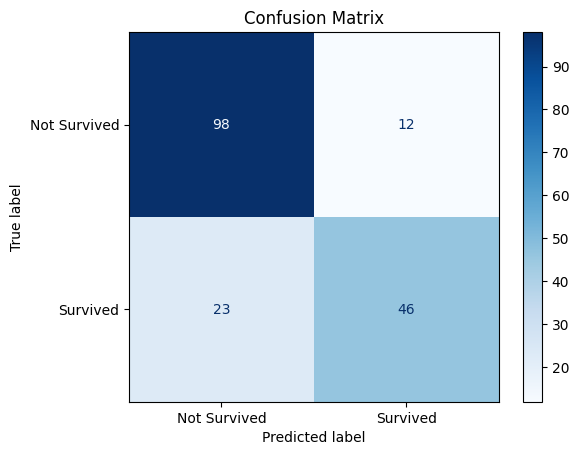

In [12]:
cm = confusion_matrix(y_val, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Survived", "Survived"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()